# CGM Metrics Computation

Computes the 19 standardised CGM metrics (basic statistics, time in range, period medians) from the preprocessed 45-day windows, aggregates them into one cohort table and plots six overview figures.

Equivalent script: `python3 -m scripts.preprocessing.cgm_metrics`.

**Usage** — from the repository root, point the notebook at a data folder and open it
(the open BrisT1D example data converted to glucose-only files is enough: `make brist1d_run`):

```bash
CGM_DATA_ROOT=$PWD/example_data/BrisT1D/converted jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the open **BrisT1D-Open** example data (Gordon James et al. 2025, CC BY 4.0), converted by `make brist1d` to glucose-only files (mg/dL, 5-min grid; see the README). These are not the study data: the numbers and figures illustrate what the code does and are not expected to match the manuscript, nor are they findings about BrisT1D.

This notebook computes standardised CGM metrics from preprocessed 45-day windows.

## Computed Metrics (19 total)

**Basic Statistics**
Mean glucose, Median glucose, SD glucose, CV (coefficient of variation)

**Time in Range Metrics**
TIR 70–180 mg/dL (target range), TAR >180 mg/dL (above range),
TAR >250 mg/dL (very high), TBR <70 mg/dL (below range), TBR <54 mg/dL (very low)

**Period-Specific Medians**
Daytime, nighttime, and other period-specific median glucose values

## Workflow

1. Load preprocessed CGM windows from `windows_summary.csv`
2. Filter invalid measurements (quality flags + NaNs)
3. Compute 19 standardised CGM metrics per patient
4. Aggregate results into a cohort-level CSV
5. Generate 6 publication-quality visualisation views

## Outputs

**Data:** `Data/Metrics/metrics_all_patients.csv` — complete metrics table

**Figures:** Glycemic control overview · Hypo/hyperglycemia risk · Diurnal pattern ·
Variability analysis · Correlation heatmap · Distribution plots


## 1. Setup & Imports

In [1]:
import os
from pathlib import Path
from typing import Dict, List

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

%matplotlib inline
from src.config import (
    PREPROCESSING_PATH,
    METRICS_PATH,
    FIG_METRICS_DIR,
    PATIENTS_STATUS_CSV,
    METRICS_CSV,
    GLUCOSE_COL,
    PATIENT_ID_COL,
    COL_HAS_WINDOW,
    COL_COVERAGE_PCT,
    COL_DOMINANT_STEP,
    COL_WIN_START,
    COL_WIN_END,
    COL_FILEPATH,
    WINDOW_SUMMARY_CSV,
)

from src.preprocessing.load_data import load_window_data
from src.preprocessing.quality import prepare_valid_data

from src.metrics.metrics import (
    compute_basic_statistics,
    compute_time_in_range_metrics,
    compute_time_based_metrics,
    compute_period_medians,
    create_empty_metrics,
    ALL_METRIC_NAMES,
    MIN_ROWS_FOR_METRICS,
    METRIC_MEAN_GLUCOSE,
    METRIC_TIR70180,
    METRIC_CV,
)

from src.visualization.metrics_plots import (
    view1_control_overview,
    view2_hypo_hyper_risk,
    view3_diurnal_pattern,
    view4_variability,
    view5_correlation_heatmap,
    plot_distribution_metrics,
)

In [2]:
from IPython.display import SVG, display


def show_saved(directory, prefix):
    """Display the saved SVG whose name starts with *prefix* (the figure helpers save and close the figure)."""
    matches = sorted(Path(directory).glob(f"{prefix}*.svg"))
    if matches:
        display(SVG(filename=str(matches[0])))
    else:
        print(f"No saved figure starting with '{prefix}' in {directory}")

## 2. Configuration

In [3]:
# Paths come from src.config (root: CGM_DATA_ROOT)
METRICS_OUTPUT_CSV = METRICS_CSV

os.makedirs(METRICS_PATH, exist_ok=True)

print("Configuration:")
print(f"  Windows summary:  {WINDOW_SUMMARY_CSV}")
print(f"  Patients status:  {PATIENTS_STATUS_CSV}")
print(f"  Output CSV:       {METRICS_OUTPUT_CSV}")
print(f"  Minimum rows for metrics: {MIN_ROWS_FOR_METRICS}")

Configuration:
  Windows summary:  <CGM_DATA_ROOT>/Data/Preprocessed/windows_summary.csv
  Patients status:  <CGM_DATA_ROOT>/Data/Preprocessed/patients_status.csv
  Output CSV:       <CGM_DATA_ROOT>/Data/Metrics/metrics_all_patients.csv
  Minimum rows for metrics: 10


## 3. Metrics Computation Functions

In [4]:
def compute_all_metrics(filepath: str) -> Dict:
    """
    Compute CGM metrics for a single patient window.

    Returns a NaN-filled dict on failure.
    """
    df = load_window_data(filepath)
    if df is None:
        return create_empty_metrics()

    df = prepare_valid_data(df)
    if len(df) < MIN_ROWS_FOR_METRICS:
        return create_empty_metrics()

    try:
        glucose = df[GLUCOSE_COL]
        metrics = {}
        metrics.update(compute_basic_statistics(glucose))
        metrics.update(compute_time_in_range_metrics(glucose))
        metrics.update(compute_time_based_metrics(df))
        metrics.update(compute_period_medians(df))
        return metrics
    except Exception:
        return create_empty_metrics()


def create_output_dataframe(rows: List[Dict]) -> pd.DataFrame:
    """Build the final structured output DataFrame in canonical column order."""
    column_order = [
        PATIENT_ID_COL,
        COL_HAS_WINDOW,
        COL_COVERAGE_PCT,
        COL_DOMINANT_STEP,
        COL_WIN_START,
        COL_WIN_END,
    ] + ALL_METRIC_NAMES
    return pd.DataFrame(rows)[column_order]

## 4. Load Patient Data

In [5]:
if not os.path.exists(WINDOW_SUMMARY_CSV):
    raise FileNotFoundError(f"windows_summary.csv not found at {WINDOW_SUMMARY_CSV}")
if not os.path.exists(PATIENTS_STATUS_CSV):
    raise FileNotFoundError(f"patients_status.csv not found at {PATIENTS_STATUS_CSV}")

summary_df  = pd.read_csv(WINDOW_SUMMARY_CSV)
status_df   = pd.read_csv(PATIENTS_STATUS_CSV)
window_info = summary_df.set_index(PATIENT_ID_COL).to_dict("index")

print(f"Total patients:           {len(status_df)}")
print(f"Patients with windows:    {len(summary_df)}")
print(f"Patients without windows: {len(status_df) - len(summary_df)}")

Total patients:           20
Patients with windows:    15
Patients without windows: 5


In [6]:
summary_df.head()

,patient_id,win_start,win_end,coverage_pct,flag_rate_pct,n_valid,n_total,dominant_step_min,filename,filepath
0,P02,2023-06-24 06:00:00,2023-08-08 06:00:00,98.60,-0.01,12779,12778,5.0,P02_win1_2023-06-24_to_2023-08-08_cov99pct.xlsx,/...
1,P03,2023-06-07 00:05:00,2023-07-22 00:05:00,99.14,-0.01,12849,12848,5.0,P03_win1_2023-06-07_to_2023-07-22_cov99pct.xlsx,/...
2,P04,2023-09-02 00:00:00,2023-10-17 00:00:00,99.14,-0.01,12848,12847,5.0,P04_win1_2023-09-02_to_2023-10-16_cov99pct.xlsx,/...
3,P07,2023-06-15 02:00:00,2023-07-30 02:00:00,98.29,-0.01,12738,12737,5.0,P07_win1_2023-06-15_to_2023-07-30_cov98pct.xlsx,/...
4,P10,2023-06-21 18:05:00,2023-08-05 18:05:00,98.06,-0.01,12709,12708,5.0,P10_win1_2023-06-21_to_2023-08-05_cov98pct.xlsx,/...


## 5. Single-Patient Test

A quick sanity-check before processing the full cohort.

In [7]:
test_patient  = summary_df.iloc[0]
test_pid      = test_patient[PATIENT_ID_COL]
test_filepath = test_patient[COL_FILEPATH]

print(f"Patient: {test_pid}")
print(f"File:    {test_filepath}")

test_metrics = compute_all_metrics(test_filepath)
print(f"\nMetrics computed: {len(test_metrics)}")

for key in [METRIC_MEAN_GLUCOSE, METRIC_TIR70180, METRIC_CV]:
    if key in test_metrics:
        v = test_metrics[key]
        if key in (METRIC_TIR70180, METRIC_CV):
            print(f"  {key}: {v*100:.1f}%" if not pd.isna(v) else f"  {key}: NaN")
        else:
            print(f"  {key}: {v:.1f}"     if not pd.isna(v) else f"  {key}: NaN")

Patient: P02
File:    <CGM_DATA_ROOT>/Data/Preprocessed/P02/P02_win1_2023-06-24_to_2023-08-08_cov99pct.xlsx



Metrics computed: 19
  Mean_glycemia: 167.5
  TIR70180: 67.3%
  CV: 30.5%


In [8]:
pd.DataFrame([test_metrics]).T.rename(columns={0: "Value"})

,Value
Mean_glycemia,167.500
Median_glycemia,158.600
Minimum_glycemia,39.600
Maximum_glycemia,400.000
SD,51.100
CV,0.305
TIR70180,0.673
TIR70140,0.318
TIR60140,0.319
TBR70,0.004


## 6. Full-Cohort Processing

In [9]:
rows   = []
errors = []

for _, row in tqdm(status_df.iterrows(), total=len(status_df), desc="Computing metrics"):
    pid        = row[PATIENT_ID_COL]
    has_window = bool(row[COL_HAS_WINDOW])

    base = {PATIENT_ID_COL: pid, COL_HAS_WINDOW: has_window}

    if not has_window or pid not in window_info:
        base.update({
            COL_COVERAGE_PCT:   None,
            COL_DOMINANT_STEP:  None,
            COL_WIN_START:      None,
            COL_WIN_END:        None,
        })
        rows.append({**base, **create_empty_metrics()})
        continue

    win      = window_info[pid]
    filepath = win[COL_FILEPATH]
    base.update(win)

    if not os.path.exists(filepath):
        errors.append(f"{pid}: missing file")
        rows.append({**base, **create_empty_metrics()})
        continue

    rows.append({**base, **compute_all_metrics(filepath)})

Computing metrics:   0%|          | 0/20 [00:00<?, ?it/s]

Computing metrics:  30%|███       | 6/20 [00:00<00:01,  9.56it/s]

Computing metrics:  35%|███▌      | 7/20 [00:01<00:02,  4.90it/s]

Computing metrics:  40%|████      | 8/20 [00:01<00:03,  3.12it/s]

Computing metrics:  45%|████▌     | 9/20 [00:02<00:04,  2.55it/s]

...

Computing metrics:  85%|████████▌ | 17/20 [00:07<00:01,  1.56it/s]

Computing metrics:  90%|█████████ | 18/20 [00:08<00:01,  1.57it/s]

Computing metrics:  95%|█████████▌| 19/20 [00:08<00:00,  1.68it/s]

Computing metrics: 100%|██████████| 20/20 [00:09<00:00,  1.65it/s]

Computing metrics: 100%|██████████| 20/20 [00:09<00:00,  2.09it/s]

In [10]:
if errors:
    print(f"{len(errors)} warnings:")
    for e in errors[:10]:
        print(f"  {e}")
    if len(errors) > 10:
        print(f"  … and {len(errors) - 10} more")
else:
    print("No processing errors.")

No processing errors.


## 7. Save & Preview Results

In [11]:
df_out = create_output_dataframe(rows)
df_out.to_csv(METRICS_OUTPUT_CSV, index=False)

print(f"Saved:                 {METRICS_OUTPUT_CSV}")
print(f"Total patients:        {len(df_out)}")
print(f"With valid metrics:    {df_out[COL_HAS_WINDOW].sum()}")

Saved:                 <CGM_DATA_ROOT>/Data/Metrics/metrics_all_patients.csv
Total patients:        20
With valid metrics:    15


In [12]:
df_out.head()

,patient_id,has_window,coverage_pct,dominant_step_min,win_start,win_end,Mean_glycemia,Median_glycemia,Minimum_glycemia,Maximum_glycemia,...,TBR70,TBR54,TAR180,TAR250,CGM_days_measured,Median_morning,Median_noon,Median_afternoon,Median_evening,Median_night
0,P01,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,P05,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,P06,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,P13,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,P21,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Cohort Summary Statistics

In [13]:
valid_df = df_out[df_out[COL_HAS_WINDOW]]

if not valid_df.empty:
    mg = valid_df[METRIC_MEAN_GLUCOSE]
    tir = valid_df[METRIC_TIR70180]
    cv  = valid_df[METRIC_CV]

    print("=" * 60)
    print("  COHORT SUMMARY")
    print("=" * 60)
    print(f"  Mean glucose     : {mg.mean():.1f} ± {mg.std():.1f} mg/dL")
    print(f"  Median TIR 70-180: {tir.median()*100:.1f}%  "
          f"(IQR {tir.quantile(.25)*100:.1f}%–{tir.quantile(.75)*100:.1f}%)")
    print(f"  Median CV        : {cv.median()*100:.1f}%  "
          f"(IQR {cv.quantile(.25)*100:.1f}%–{cv.quantile(.75)*100:.1f}%)")
    print("=" * 60)
else:
    print("No valid metrics to summarise.")

  COHORT SUMMARY
  Mean glucose     : 151.3 ± 15.7 mg/dL
  Median TIR 70-180: 73.8%  (IQR 68.1%–77.2%)
  Median CV        : 33.9%  (IQR 30.8%–36.0%)


## 8. Visualisations

Each view calls its plotting function and then `plt.show()` so the figure is
saved to `Figures/Metrics/` and displayed here.

### View 1 — Glycemic Control Overview


─── View 1: Glycaemic control overview ───


Saved: view1_mean_vs_TIR70180_hue_CV_mgdl.{pdf,svg}  (DPI: 600)


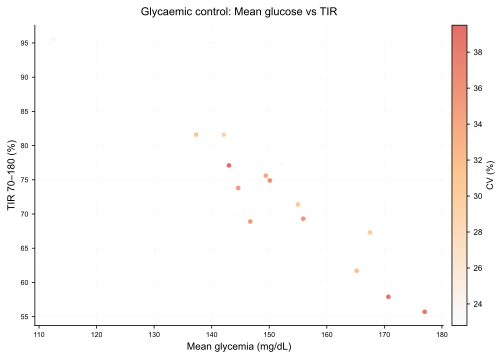

In [14]:
view1_control_overview(df_out)
show_saved(FIG_METRICS_DIR, "view1")

### View 2 — Hypo / Hyperglycemia Risk


─── View 2: Hypo / hyperglycaemia risk profile ───


Saved: view2_TBR70_vs_TAR180_hue_TIR70180_mgdl.{pdf,svg}  (DPI: 600)


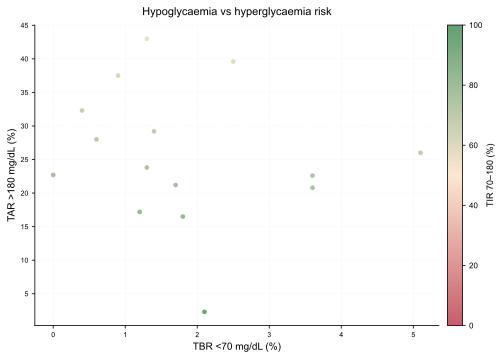

In [15]:
view2_hypo_hyper_risk(df_out)
show_saved(FIG_METRICS_DIR, "view2")

### View 3 — Diurnal Pattern


─── View 3: Diurnal glycaemic pattern ───


Saved: view3_diurnal_medians_mgdl.{pdf,svg}  (DPI: 600)


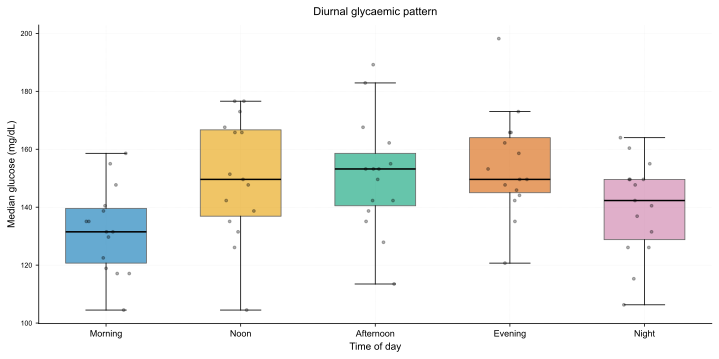

In [16]:
view3_diurnal_pattern(df_out)
show_saved(FIG_METRICS_DIR, "view3")

### View 4 — Variability Analysis


─── View 4: Variability deep-dive ───


Saved: view4_CV_vs_SD_hue_mean_size_days_mgdl.{pdf,svg}  (DPI: 600)


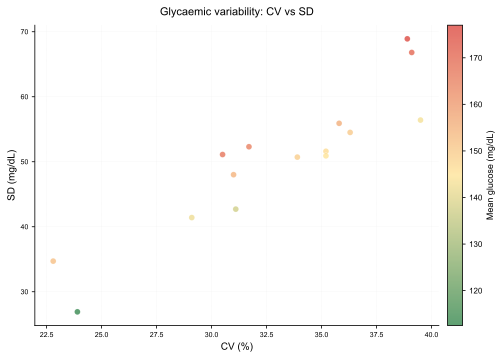

In [17]:
view4_variability(df_out)
show_saved(FIG_METRICS_DIR, "view4")

### View 5 — Correlation Heatmap


─── View 5: Metric correlation heatmap ───


Saved: view5_correlation_heatmap.{pdf,svg}  (DPI: 600)


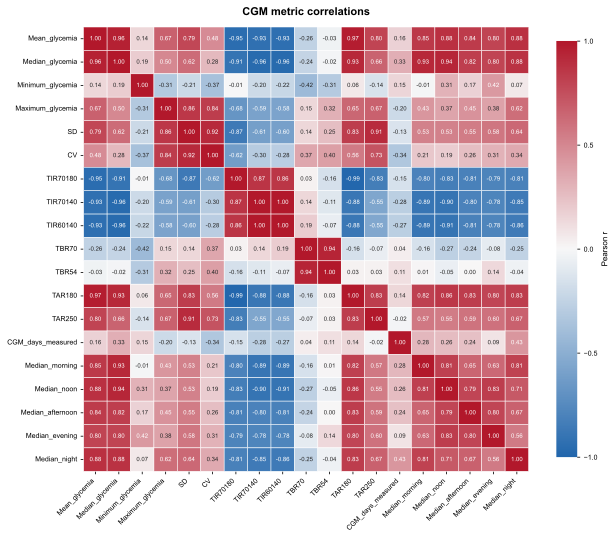

In [18]:
view5_correlation_heatmap(df_out)
show_saved(FIG_METRICS_DIR, "view5")

### View 6 — Metric Distributions


─── Supplementary Figure S1: Metric distributions ───


Saved: suppfig_s1_metric_distributions_mgdl.{pdf,svg}  (DPI: 600)


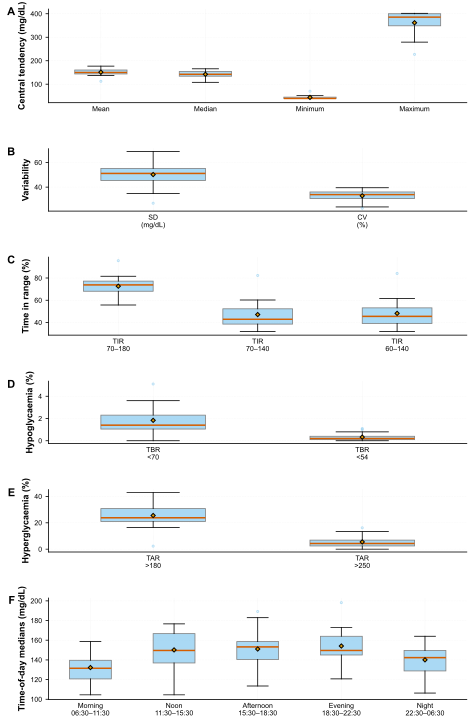

In [19]:
plot_distribution_metrics(df_out)
show_saved(FIG_METRICS_DIR, "suppfig_s1")